In [1]:
from collections import Counter
from pathlib import Path
import sys

repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root / "src"))

from data.datasets import get_dataset
from data.splits import get_train_val_split

dataset_name = "Oxford-IIIT Pet classification"
data_dir = repo_root / "data" / "raw" / "iit_pet"

# Keep samples raw until statistics have been computed on the training split.
trainval_dataset = get_dataset(
    split="trainval", dataset=dataset_name, data_dir=data_dir, download=False
)
raw_test_dataset = get_dataset(
    split="test", dataset=dataset_name, data_dir=data_dir, download=False
)

raw_train_dataset, raw_val_dataset = get_train_val_split(
    trainval_dataset, ratio=0.2, seed=42, labels=trainval_dataset._labels
)

assert set(raw_train_dataset.indices).isdisjoint(raw_val_dataset.indices)
for name, subset in (("Train", raw_train_dataset), ("Validation", raw_val_dataset)):
    counts = Counter(trainval_dataset._labels[i] for i in subset.indices)
    print(
        f"{name}: {len(subset)} images, {len(counts)} classes "
        f"({min(counts.values())}-{max(counts.values())} per class)"
    )
print(f"Test: {len(raw_test_dataset)} images (official held-out set)")
image, label = raw_train_dataset[0]
print(f"Example: image size={image.size}, label={label}")


Train: 2944 images, 37 classes (74-80 per class)
Validation: 736 images, 37 classes (19-20 per class)
Test: 3669 images (official held-out set)
Example: image size=(460, 500), label=33


In [2]:
from functools import partial
from torch.utils.data import Subset
from data.datasets import calculate_mean_std
from data.dataloaders import get_dataloader
from data.transforms import image_transform

NUM_WORKERS = 4
BATCH_SIZE = 32
IMAGE_SIZE = (224, 224)

mean, std = calculate_mean_std(raw_train_dataset, size=IMAGE_SIZE)
print("Train-only RGB mean/std:", mean, std)

train_transform = partial(image_transform, mean=mean, std=std, train=True, size=IMAGE_SIZE)
eval_transform = partial(image_transform, mean=mean, std=std, train=False, size=IMAGE_SIZE)

train_dataset = Subset(
    get_dataset("trainval", dataset_name, data_dir, transform=train_transform),
    raw_train_dataset.indices,
)
val_dataset = Subset(
    get_dataset("trainval", dataset_name, data_dir, transform=eval_transform),
    raw_val_dataset.indices,
)
test_dataset = get_dataset("test", dataset_name, data_dir, transform=eval_transform)

train_dataloader = get_dataloader(
    train_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS
)
val_dataloader = get_dataloader(
    val_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS
)
test_dataloader = get_dataloader(
    test_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS
)

for split_name, loader in (
    ("train", train_dataloader), ("validation", val_dataloader), ("test", test_dataloader)
):
    images, labels = next(iter(loader))
    print(f"{split_name}: images={tuple(images.shape)}, labels={tuple(labels.shape)}")


Train-only RGB mean/std: (0.47900132099122517, 0.4459370107439885, 0.3957552987561295) (0.26277782885776046, 0.25720866943272247, 0.2647733334484445)
train: images=(32, 3, 224, 224), labels=(32,)
validation: images=(32, 3, 224, 224), labels=(32,)
test: images=(32, 3, 224, 224), labels=(32,)


In [3]:
import copy
from models import get_classification_model

convnext_model = get_classification_model("convnext_tiny", pretrained=True, num_classes=37)
swin_transformer_model = get_classification_model("swin_tiny_patch4_window7_224", pretrained=True, num_classes=37)
resnet50_model = get_classification_model("resnet50", pretrained=True, num_classes=37)


initial_model_states = {
    "convnext_tiny": copy.deepcopy(convnext_model.state_dict()),
    "swin_tiny": copy.deepcopy(swin_transformer_model.state_dict()),
    "resnet50": copy.deepcopy(resnet50_model.state_dict()),
}


/Users/kasrasadatsharifi/Library/Caches/pypoetry/virtualenvs/convnexts-2-MddwQV-py3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Head-only classifier training


Matplotlib is building the font cache; this may take a moment.


Training classification head: ConvNeXt Tiny
Trainable: 28,453/27,848,581 (0.1%)
Epoch 1/10: train_loss=2.7527, train_acc=0.3499, val_loss=1.7290, val_acc=0.7418
Epoch 2/10: train_loss=1.2230, train_acc=0.8128, val_loss=0.8234, val_acc=0.8832
Epoch 3/10: train_loss=0.6625, train_acc=0.8981, val_loss=0.5363, val_acc=0.9090
Epoch 4/10: train_loss=0.4747, train_acc=0.9124, val_loss=0.4146, val_acc=0.9212
Epoch 5/10: train_loss=0.3698, train_acc=0.9287, val_loss=0.3487, val_acc=0.9280
Epoch 6/10: train_loss=0.3094, train_acc=0.9385, val_loss=0.3081, val_acc=0.9280
Epoch 7/10: train_loss=0.2632, train_acc=0.9477, val_loss=0.2806, val_acc=0.9293
Epoch 8/10: train_loss=0.2377, train_acc=0.9494, val_loss=0.2602, val_acc=0.9361
Epoch 9/10: train_loss=0.2202, train_acc=0.9511, val_loss=0.2466, val_acc=0.9402
Epoch 10/10: train_loss=0.1909, train_acc=0.9596, val_loss=0.2332, val_acc=0.9402


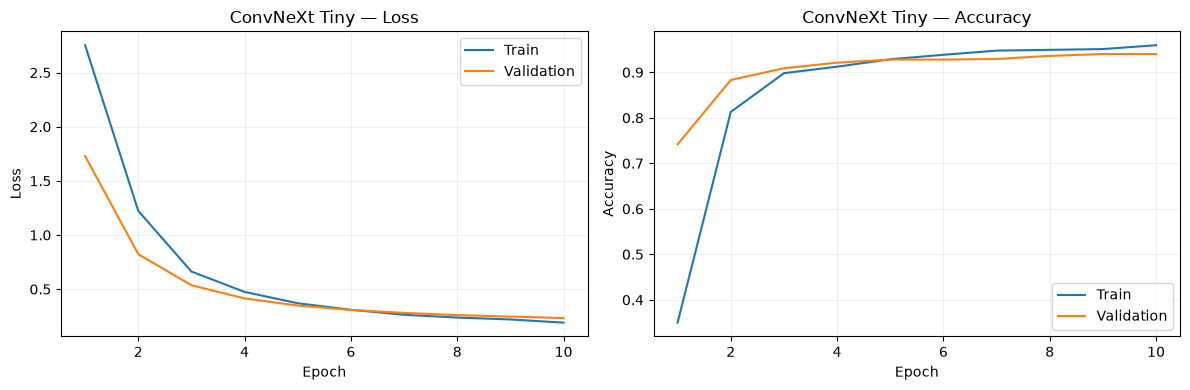

Best ConvNeXt Tiny: epoch=10, val_acc=0.9402
Training classification head: Swin Transformer Tiny
Trainable: 28,453/27,547,807 (0.1%)
Epoch 1/10: train_loss=3.2210, train_acc=0.3828, val_loss=2.7986, val_acc=0.6861
Epoch 2/10: train_loss=2.4876, train_acc=0.7520, val_loss=2.1329, val_acc=0.8356
Epoch 3/10: train_loss=1.8967, train_acc=0.8380, val_loss=1.6166, val_acc=0.8791
Epoch 4/10: train_loss=1.4542, train_acc=0.8835, val_loss=1.2444, val_acc=0.9049
Epoch 5/10: train_loss=1.1400, train_acc=0.8984, val_loss=0.9908, val_acc=0.9117
Epoch 6/10: train_loss=0.9270, train_acc=0.9168, val_loss=0.8174, val_acc=0.9212
Epoch 7/10: train_loss=0.7766, train_acc=0.9175, val_loss=0.6964, val_acc=0.9239
Epoch 8/10: train_loss=0.6716, train_acc=0.9276, val_loss=0.6091, val_acc=0.9253
Epoch 9/10: train_loss=0.5946, train_acc=0.9243, val_loss=0.5438, val_acc=0.9293
Epoch 10/10: train_loss=0.5290, train_acc=0.9307, val_loss=0.4938, val_acc=0.9266


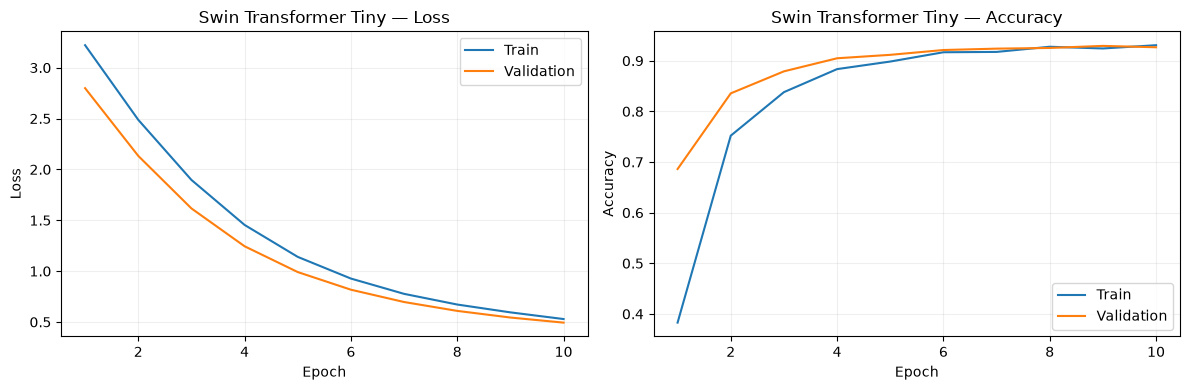

Best Swin Transformer Tiny: epoch=9, val_acc=0.9293
Training classification head: ResNet-50
Trainable: 75,813/23,583,845 (0.3%)
Epoch 1/10: train_loss=3.4564, train_acc=0.3132, val_loss=3.2959, val_acc=0.5897
Epoch 2/10: train_loss=3.1509, train_acc=0.7361, val_loss=3.0122, val_acc=0.8111
Epoch 3/10: train_loss=2.8723, train_acc=0.8590, val_loss=2.7500, val_acc=0.8601
Epoch 4/10: train_loss=2.6117, train_acc=0.8899, val_loss=2.5062, val_acc=0.8872
Epoch 5/10: train_loss=2.3761, train_acc=0.9100, val_loss=2.2820, val_acc=0.8954
Epoch 6/10: train_loss=2.1566, train_acc=0.9178, val_loss=2.0768, val_acc=0.8981
Epoch 7/10: train_loss=1.9517, train_acc=0.9293, val_loss=1.8893, val_acc=0.9062
Epoch 8/10: train_loss=1.7741, train_acc=0.9253, val_loss=1.7208, val_acc=0.9103
Epoch 9/10: train_loss=1.6077, train_acc=0.9324, val_loss=1.5692, val_acc=0.9103
Epoch 10/10: train_loss=1.4688, train_acc=0.9331, val_loss=1.4355, val_acc=0.9130


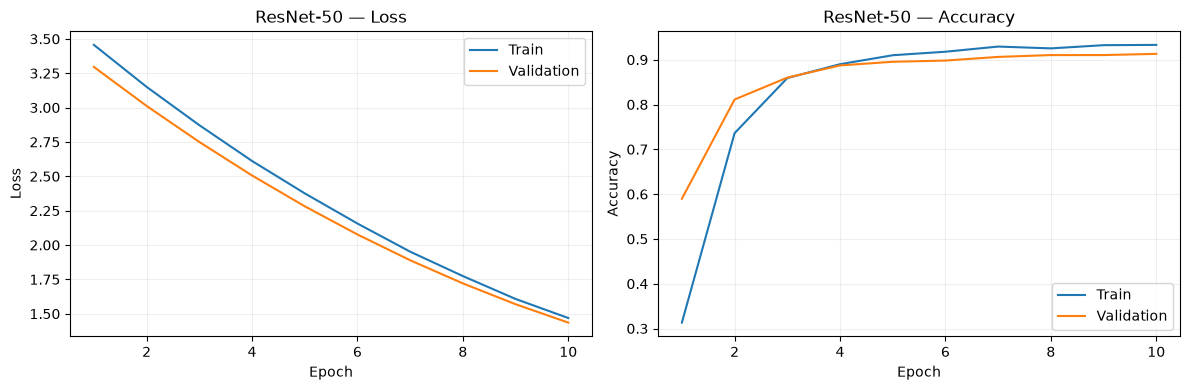

Best ResNet-50: epoch=10, val_acc=0.9130


In [ ]:
import torch
from evaluation import train_one_epoch, validate
from utils.io import save_checkpoint, save_json
from visualization import plot_training_history

NUM_EPOCHS = 10
DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {DEVICE}")
CRITERION = torch.nn.CrossEntropyLoss()
LEARNING_RATE = 1e-4

models = {
    "ConvNeXt Tiny": ("convnext_tiny", convnext_model),
    "Swin Transformer Tiny": ("swin_tiny", swin_transformer_model),
    "ResNet-50": ("resnet50", resnet50_model),
}

training_runs = {}
for model_name, (model_id, model) in models.items():
    print(f"Training classification head: {model_name}")
    model.load_state_dict(initial_model_states[model_id])
    model.to(DEVICE)

    for parameter in model.parameters():
        parameter.requires_grad = False
    for parameter in model.get_classifier().parameters():
        parameter.requires_grad = True

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable: {trainable:,}/{total:,} ({trainable/total:.1%})")

    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad), lr=LEARNING_RATE
    )
    result_dir = repo_root / "results" / "classification" / "classifier_head" / model_id
    history = []
    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = None

    for epoch in range(1, NUM_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_dataloader, CRITERION, optimizer, DEVICE
        )
        val_loss, val_acc = validate(model, val_dataloader, CRITERION, DEVICE)
        history.append({
            "epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc,
        })
        print(
            f"Epoch {epoch}/{NUM_EPOCHS}: train_loss={train_loss:.4f}, "
            f"train_acc={train_acc:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}"
        )

        if val_acc > best_val_accuracy or (
            val_acc == best_val_accuracy and val_loss < best_val_loss
        ):
            best_epoch = epoch
            best_val_accuracy = val_acc
            best_val_loss = val_loss
            save_checkpoint(
                result_dir / "best.pt", model, optimizer, epoch,
                {"loss": val_loss, "accuracy": val_acc},
                metadata={
                    "model_name": model_name, "model_id": model_id,
                    "dataset": dataset_name, "training_strategy": "head_only",
                    "learning_rate": LEARNING_RATE, "image_size": IMAGE_SIZE,
                    "normalization_mean": mean, "normalization_std": std,
                    "split_seed": 42, "trainable_parameters": trainable,
                    "initialization": "pretrained_backbone_fresh_classifier",
                },
            )

        save_json(history, result_dir / "training_history.json")

    training_runs[model_name] = {
        "model_id": model_id, "history": history,
        "best_epoch": best_epoch, "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
    }
    plot_training_history(history, model_name)
    print(f"Best {model_name}: epoch={best_epoch}, val_acc={best_val_accuracy:.4f}")


In [5]:
from evaluation import evaluate
from utils.io import load_checkpoint, save_json, save_predictions
from visualization import display_metrics, plot_confusion_matrix, plot_AUC_ROC, plot_AUC_PR

test_results = {}
test_predictions = {}
for model_name, (model_id, model) in models.items():
    result_dir = repo_root / "results" / "classification" / "classifier_head" / model_id
    checkpoint = load_checkpoint(result_dir / "best.pt", model, device=DEVICE)
    metrics, predictions = evaluate(
        model, test_dataloader, CRITERION, DEVICE, return_predictions=True
    )
    test_results[model_name] = metrics
    test_predictions[model_name] = predictions
    save_json(
        {
            "model": model_name,
            "checkpoint_epoch": checkpoint["epoch"],
            "best_validation": checkpoint["validation_metrics"],
            "test_metrics": metrics,
        },
        result_dir / "test_metrics.json",
    )
    save_predictions(predictions, result_dir / "test_predictions.npz")

comparison = display_metrics(test_results)
save_json(test_results, repo_root / "results" / "classification" / "classifier_head" / "comparison.json")


,Loss,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AP (macro OvR),ECE,Classes in AUC
Model,,,,,,,,,,,,
ConvNeXt Tiny,0.2737,0.9182,0.9192,0.9180,0.9170,0.9200,0.9182,0.9175,0.9984,0.9539,0.0538,37
Swin Transformer Tiny,0.5684,0.9087,0.9099,0.9082,0.9071,0.9108,0.9087,0.9078,0.9980,0.9486,0.2656,37
ResNet-50,1.4801,0.8945,0.8947,0.8940,0.8919,0.8955,0.8945,0.8925,0.9960,0.9043,0.6406,37


PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/classification/classifier_head/comparison.json')

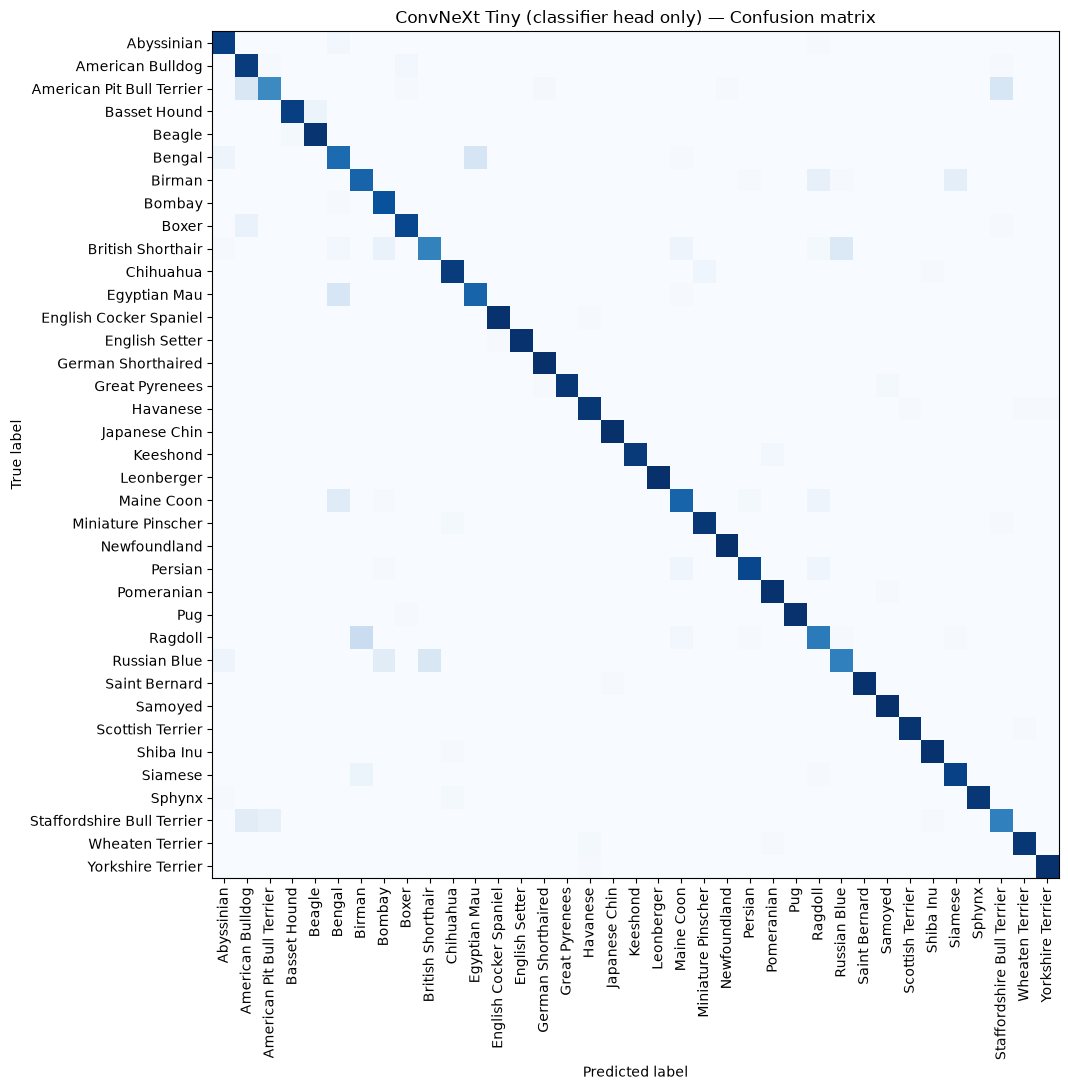

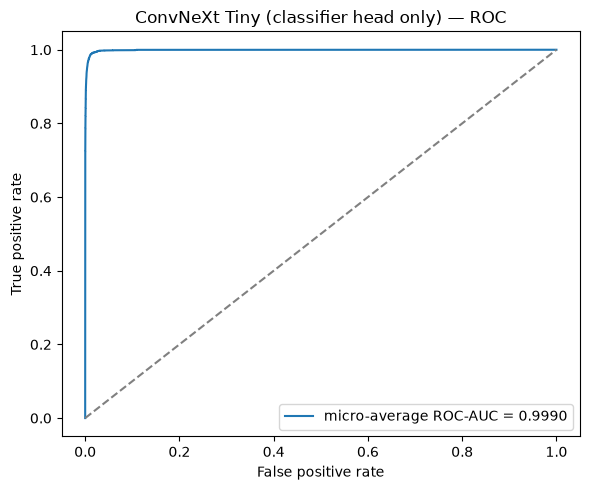

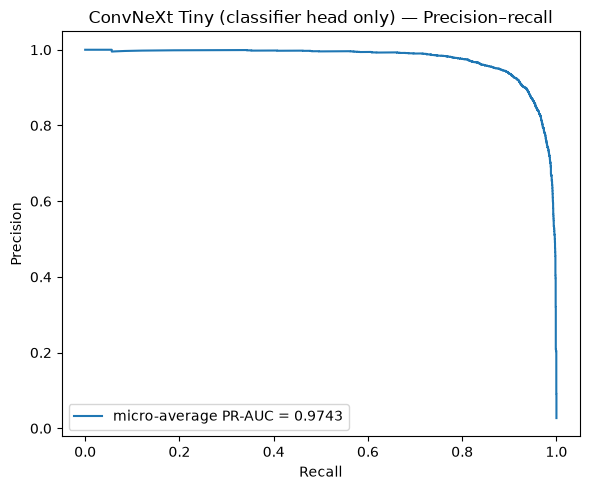

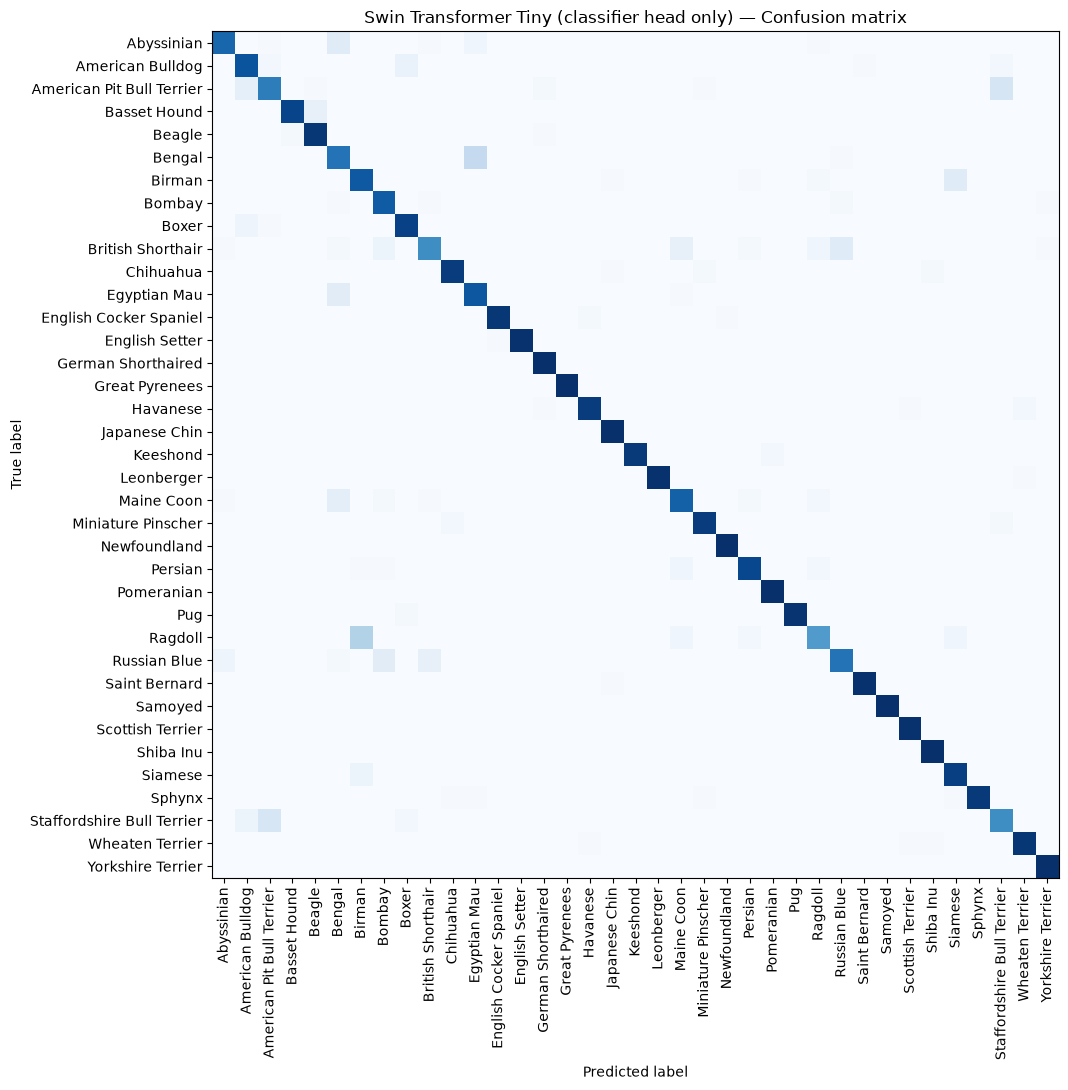

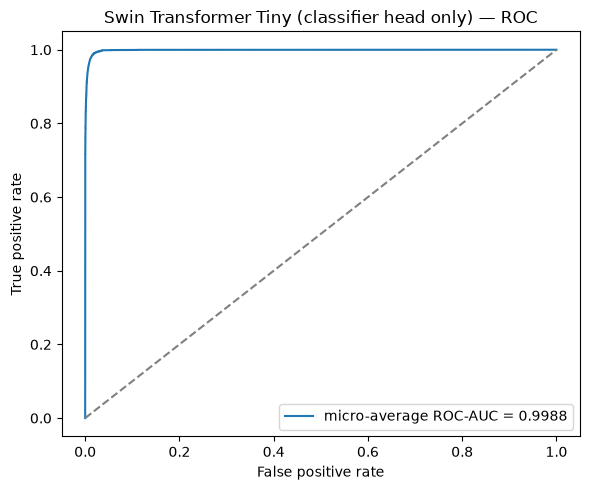

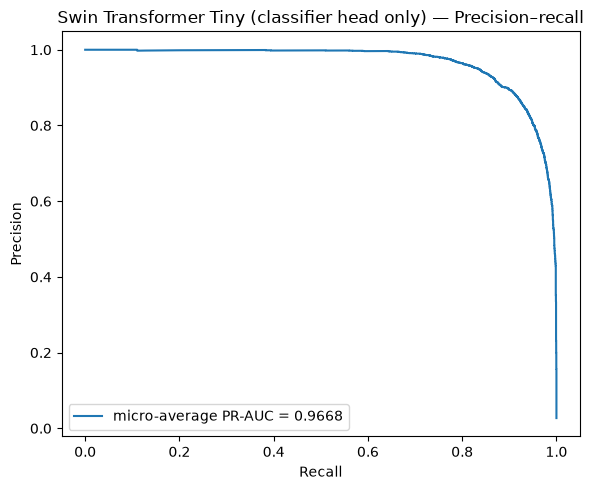

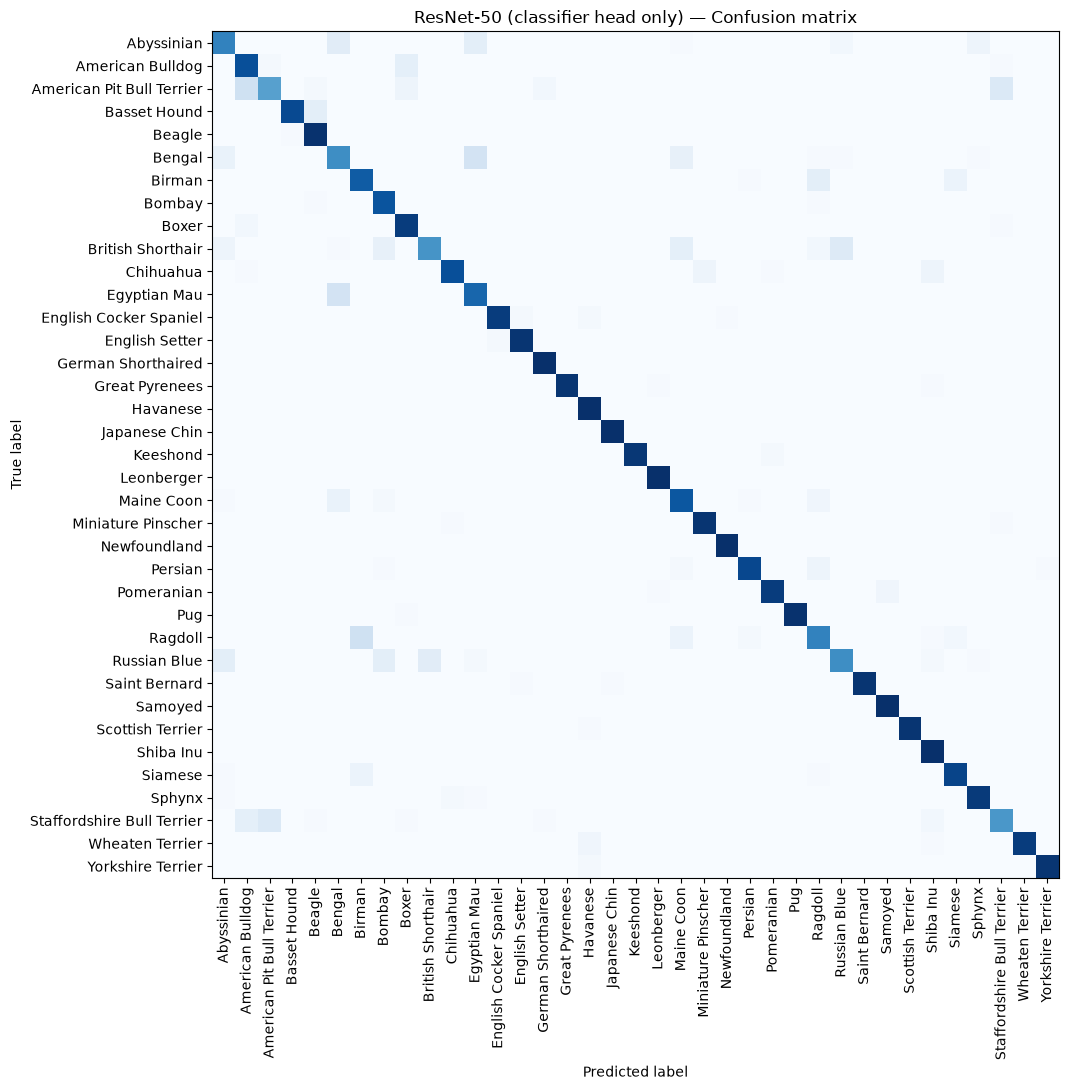

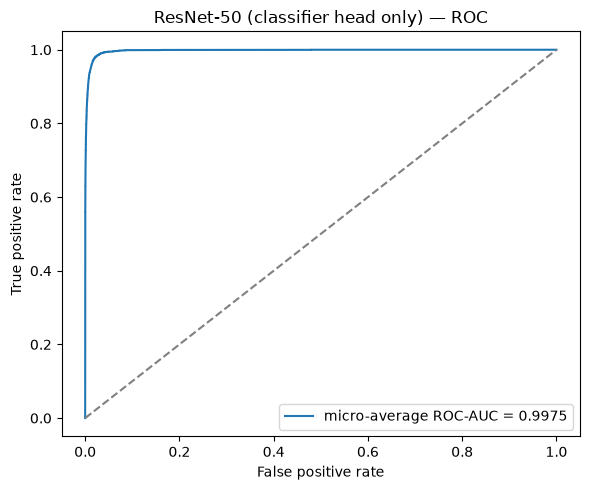

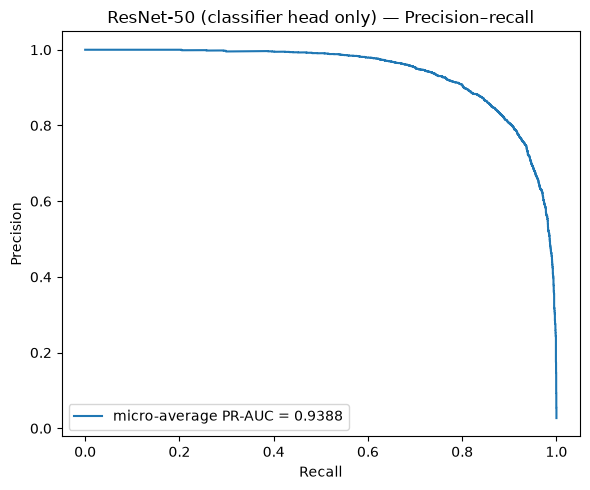

In [6]:
for name, result in test_results.items():
    predictions = test_predictions[name]
    title = f"{name} ({"classifier head only"})"
    plot_confusion_matrix(
        result["confusion_matrix"], title, class_names=test_dataset.classes
    )
    plot_AUC_ROC(predictions["labels"], predictions["probabilities"], title)
    plot_AUC_PR(predictions["labels"], predictions["probabilities"], title)


# fine tune more layers

Fine-tuning final stage and classifier: ConvNeXt Tiny
Trainable: 15,500,581/27,848,581 (55.7%)
Epoch 1/10: train_loss=1.7922, train_acc=0.6111, val_loss=0.4997, val_acc=0.9103
Epoch 2/10: train_loss=0.3163, train_acc=0.9351, val_loss=0.2792, val_acc=0.9321
Epoch 3/10: train_loss=0.1677, train_acc=0.9603, val_loss=0.2098, val_acc=0.9497
Epoch 4/10: train_loss=0.1049, train_acc=0.9783, val_loss=0.2086, val_acc=0.9443
Epoch 5/10: train_loss=0.0740, train_acc=0.9813, val_loss=0.1774, val_acc=0.9470
Epoch 6/10: train_loss=0.0528, train_acc=0.9915, val_loss=0.1863, val_acc=0.9457
Epoch 7/10: train_loss=0.0382, train_acc=0.9942, val_loss=0.1626, val_acc=0.9511
Epoch 8/10: train_loss=0.0301, train_acc=0.9959, val_loss=0.1789, val_acc=0.9524
Epoch 9/10: train_loss=0.0225, train_acc=0.9980, val_loss=0.1659, val_acc=0.9565
Epoch 10/10: train_loss=0.0156, train_acc=0.9993, val_loss=0.1643, val_acc=0.9524


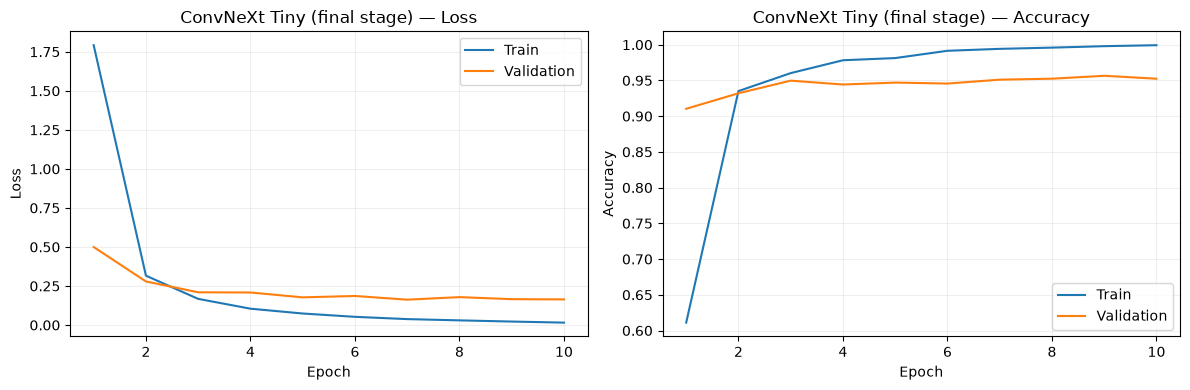

Best ConvNeXt Tiny: epoch=9, val_acc=0.9565
Fine-tuning final stage and classifier: Swin Transformer Tiny
Trainable: 15,396,565/27,547,807 (55.9%)
Epoch 1/10: train_loss=2.9398, train_acc=0.4423, val_loss=1.8654, val_acc=0.7948
Epoch 2/10: train_loss=1.0945, train_acc=0.8390, val_loss=0.4978, val_acc=0.9144
Epoch 3/10: train_loss=0.4651, train_acc=0.9137, val_loss=0.3036, val_acc=0.9348
Epoch 4/10: train_loss=0.3027, train_acc=0.9375, val_loss=0.2487, val_acc=0.9389
Epoch 5/10: train_loss=0.2367, train_acc=0.9552, val_loss=0.2038, val_acc=0.9484
Epoch 6/10: train_loss=0.1976, train_acc=0.9613, val_loss=0.1870, val_acc=0.9457
Epoch 7/10: train_loss=0.1610, train_acc=0.9674, val_loss=0.1864, val_acc=0.9457
Epoch 8/10: train_loss=0.1388, train_acc=0.9735, val_loss=0.1716, val_acc=0.9470
Epoch 9/10: train_loss=0.1202, train_acc=0.9776, val_loss=0.1737, val_acc=0.9484
Epoch 10/10: train_loss=0.1079, train_acc=0.9793, val_loss=0.1732, val_acc=0.9457


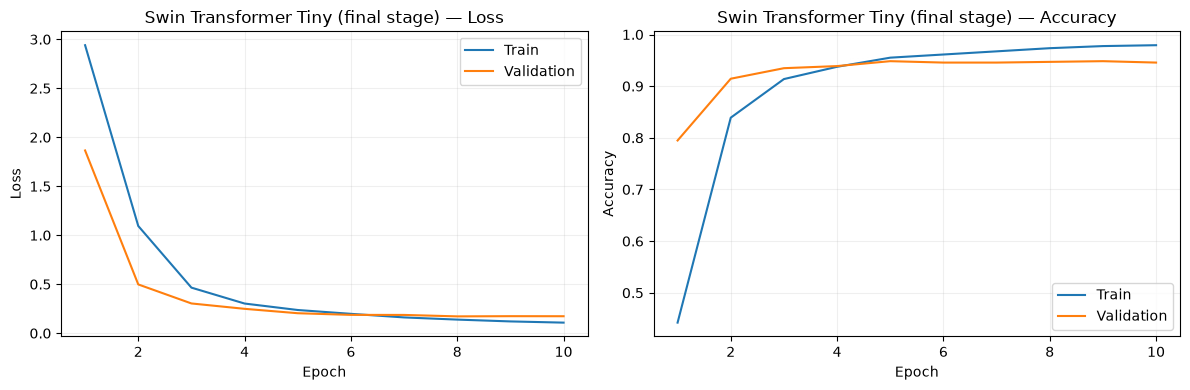

Best Swin Transformer Tiny: epoch=9, val_acc=0.9484
Fine-tuning final stage and classifier: ResNet-50
Trainable: 15,040,549/23,583,845 (63.8%)
Epoch 1/10: train_loss=3.4704, train_acc=0.2826, val_loss=3.2807, val_acc=0.5924
Epoch 2/10: train_loss=3.1371, train_acc=0.6940, val_loss=2.8864, val_acc=0.8139
Epoch 3/10: train_loss=2.7420, train_acc=0.8281, val_loss=2.4446, val_acc=0.8573
Epoch 4/10: train_loss=2.3005, train_acc=0.8757, val_loss=1.9639, val_acc=0.8832
Epoch 5/10: train_loss=1.8479, train_acc=0.8899, val_loss=1.5030, val_acc=0.8859
Epoch 6/10: train_loss=1.4448, train_acc=0.8967, val_loss=1.1300, val_acc=0.8913
Epoch 7/10: train_loss=1.1338, train_acc=0.9008, val_loss=0.8955, val_acc=0.9008
Epoch 8/10: train_loss=0.9047, train_acc=0.9008, val_loss=0.7167, val_acc=0.9144
Epoch 9/10: train_loss=0.7464, train_acc=0.9141, val_loss=0.5971, val_acc=0.9171
Epoch 10/10: train_loss=0.6458, train_acc=0.9151, val_loss=0.5065, val_acc=0.9076


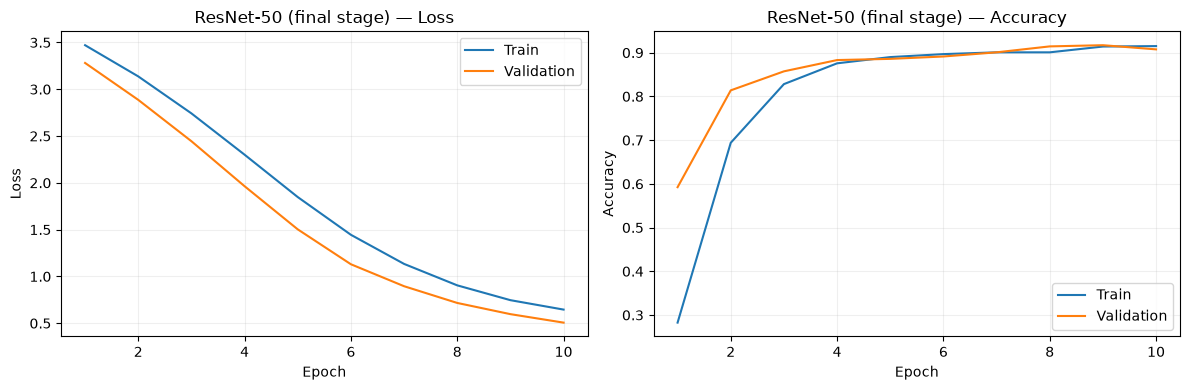

Best ResNet-50: epoch=9, val_acc=0.9171


In [7]:
BACKBONE_LEARNING_RATE = 1e-5
HEAD_LEARNING_RATE = 1e-4

training_runs = {}
for model_name, (model_id, model) in models.items():
    print(f"Fine-tuning final stage and classifier: {model_name}")
    model.load_state_dict(initial_model_states[model_id])
    model.to(DEVICE)

    for parameter in model.parameters():
        parameter.requires_grad = False

    if model_id == "convnext_tiny":
        modules_to_train = [model.stages[-1], model.head]
    elif model_id == "swin_tiny":
        modules_to_train = [model.layers[-1], model.norm, model.head]
    elif model_id == "resnet50":
        modules_to_train = [model.layer4, model.fc]
    else:
        raise ValueError(f"Unexpected model: {model_id}")

    for module in modules_to_train:
        for parameter in module.parameters():
            parameter.requires_grad = True

    head_params = list(model.get_classifier().parameters())
    head_ids = {id(param) for param in head_params}
    backbone_params = [
        param for param in model.parameters()
        if param.requires_grad and id(param) not in head_ids
    ]
    assert backbone_params and head_params, "Final-stage training needs both groups."

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable: {trainable:,}/{total:,} ({trainable/total:.1%})")

    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": BACKBONE_LEARNING_RATE},
        {"params": head_params, "lr": HEAD_LEARNING_RATE},
    ])
    result_dir = repo_root / "results" / "classification" / "partial" / model_id
    history = []
    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = None

    for epoch in range(1, NUM_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_dataloader, CRITERION, optimizer, DEVICE
        )
        val_loss, val_acc = validate(model, val_dataloader, CRITERION, DEVICE)
        history.append({
            "epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc,
        })
        print(
            f"Epoch {epoch}/{NUM_EPOCHS}: train_loss={train_loss:.4f}, "
            f"train_acc={train_acc:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}"
        )

        if val_acc > best_val_accuracy or (
            val_acc == best_val_accuracy and val_loss < best_val_loss
        ):
            best_epoch = epoch
            best_val_accuracy = val_acc
            best_val_loss = val_loss
            save_checkpoint(
                result_dir / "best.pt", model, optimizer, epoch,
                {"loss": val_loss, "accuracy": val_acc},
                metadata={
                    "model_name": model_name, "model_id": model_id,
                    "dataset": dataset_name, "training_strategy": "final_stage",
                    "backbone_learning_rate": BACKBONE_LEARNING_RATE,
                    "head_learning_rate": HEAD_LEARNING_RATE,
                    "image_size": IMAGE_SIZE,
                    "normalization_mean": mean, "normalization_std": std,
                    "split_seed": 42, "trainable_parameters": trainable,
                    "initialization": "pretrained_backbone_fresh_classifier",
                },
            )

        save_json(history, result_dir / "training_history.json")

    training_runs[model_name] = {
        "model_id": model_id, "history": history,
        "best_epoch": best_epoch, "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
    }
    plot_training_history(history, f"{model_name} (final stage)")
    print(f"Best {model_name}: epoch={best_epoch}, val_acc={best_val_accuracy:.4f}")


In [8]:
test_results = {}
test_predictions = {}
for model_name, (model_id, model) in models.items():
    result_dir = repo_root / "results" / "classification" / "partial" / model_id
    checkpoint = load_checkpoint(result_dir / "best.pt", model, device=DEVICE)
    metrics, predictions = evaluate(
        model, test_dataloader, CRITERION, DEVICE, return_predictions=True
    )
    test_results[model_name] = metrics
    test_predictions[model_name] = predictions
    save_json(
        {
            "model": model_name,
            "checkpoint_epoch": checkpoint["epoch"],
            "best_validation": checkpoint["validation_metrics"],
            "test_metrics": metrics,
        },
        result_dir / "test_metrics.json",
    )
    save_predictions(predictions, result_dir / "test_predictions.npz")

comparison = display_metrics(test_results)
save_json(test_results, repo_root / "results" / "classification" / "partial" / "comparison.json")


,Loss,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AP (macro OvR),ECE,Classes in AUC
Model,,,,,,,,,,,,
ConvNeXt Tiny,0.2254,0.9354,0.9369,0.9351,0.9341,0.9378,0.9354,0.9347,0.9984,0.9674,0.0129,37
Swin Transformer Tiny,0.2069,0.9286,0.9300,0.9278,0.9271,0.9304,0.9286,0.9277,0.9989,0.9686,0.0101,37
ResNet-50,0.6397,0.8942,0.8950,0.8939,0.8913,0.8960,0.8942,0.8920,0.9969,0.9284,0.2680,37


PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/classification/partial/comparison.json')

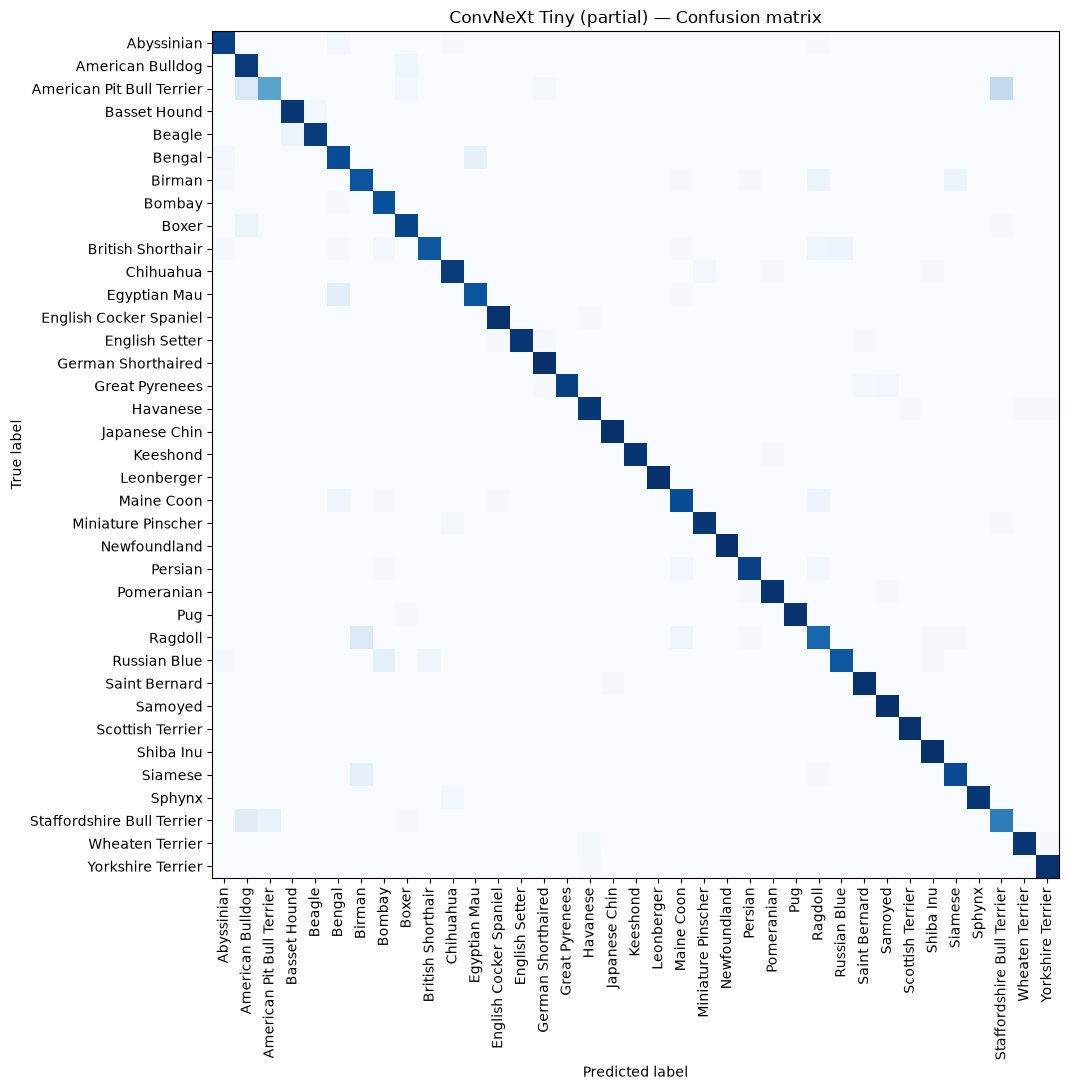

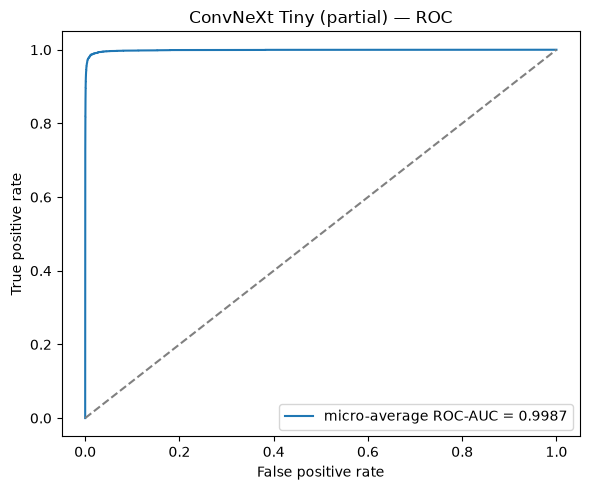

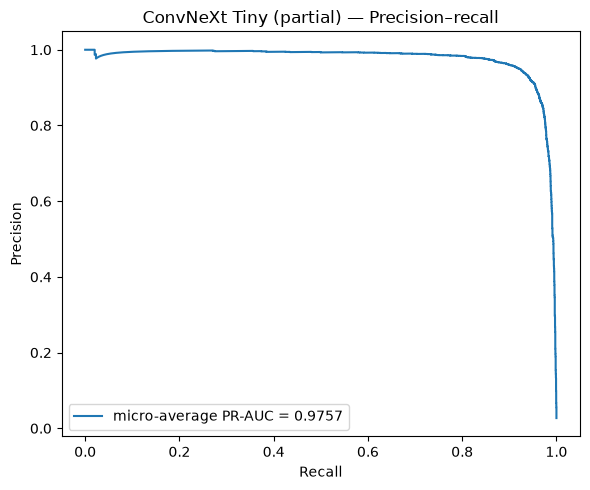

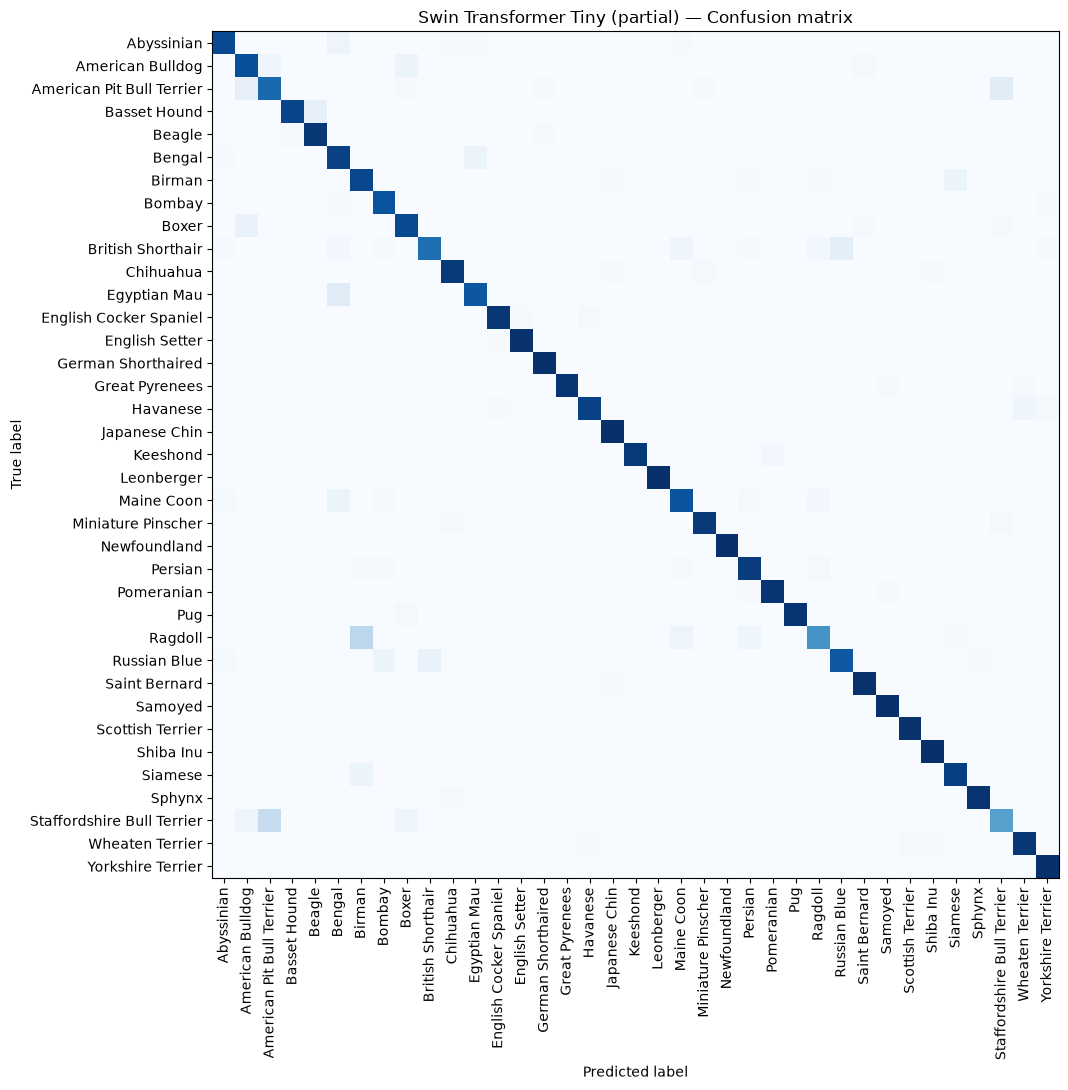

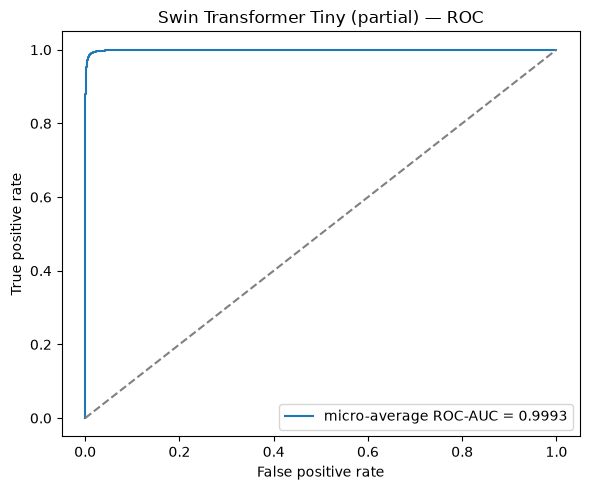

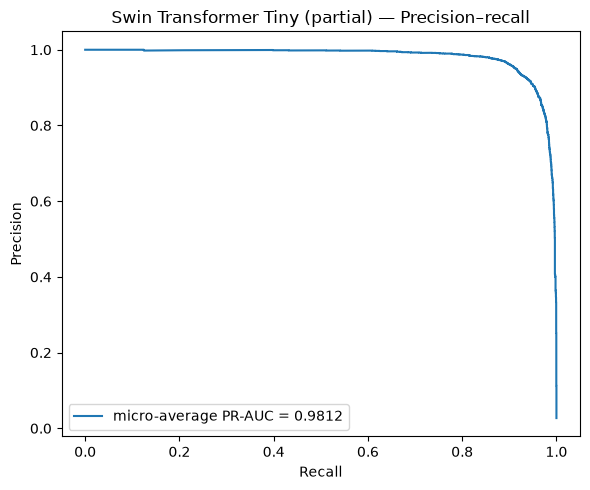

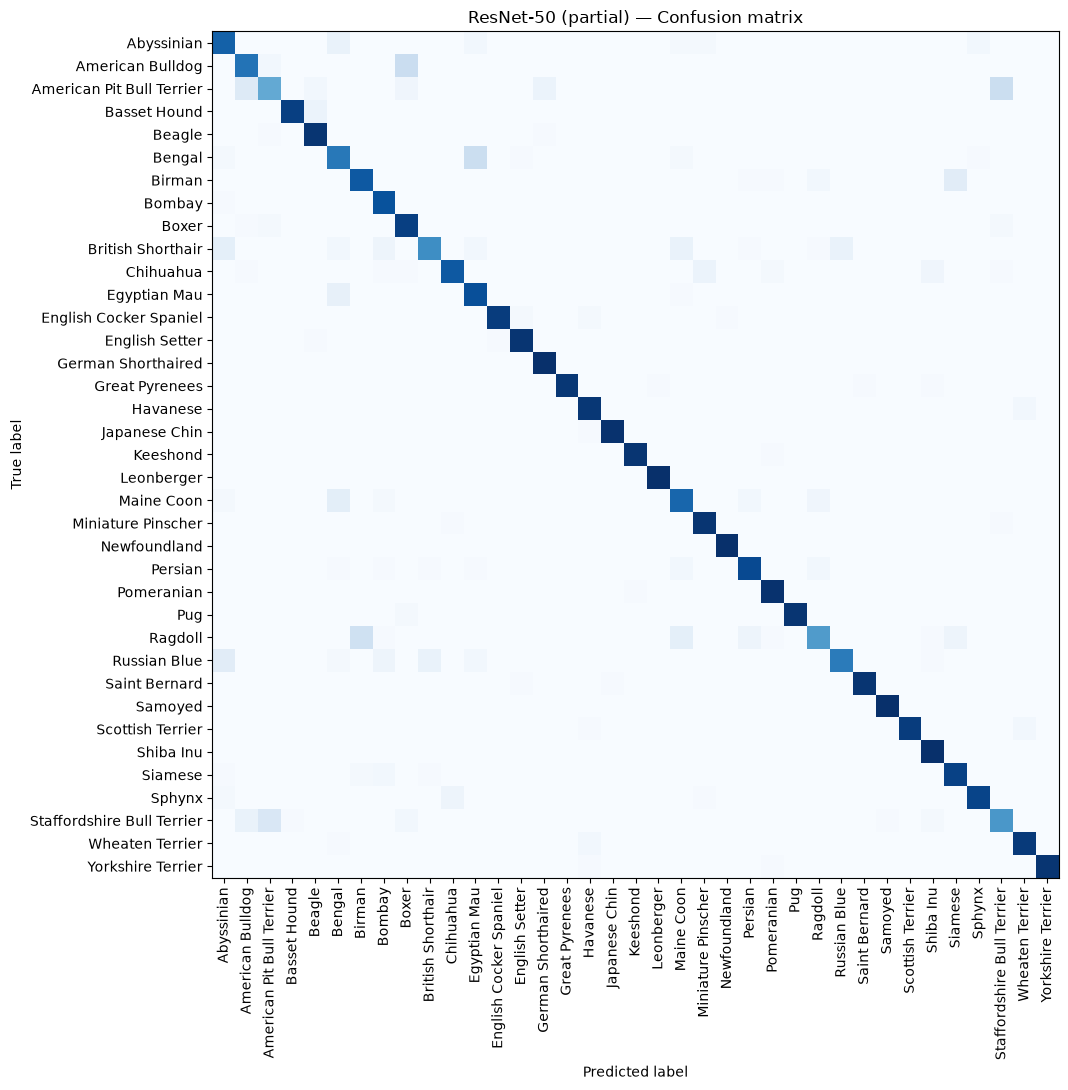

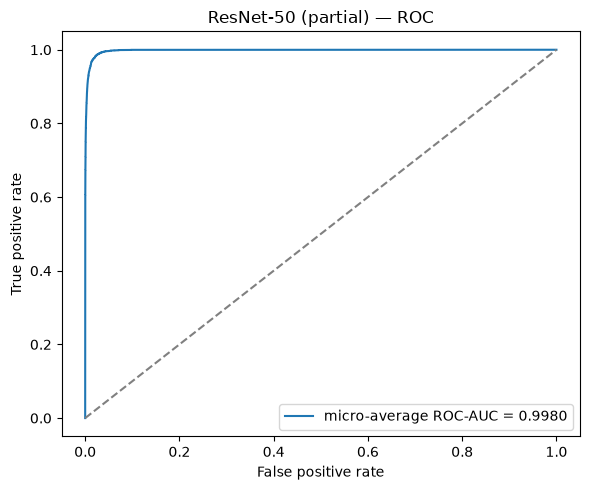

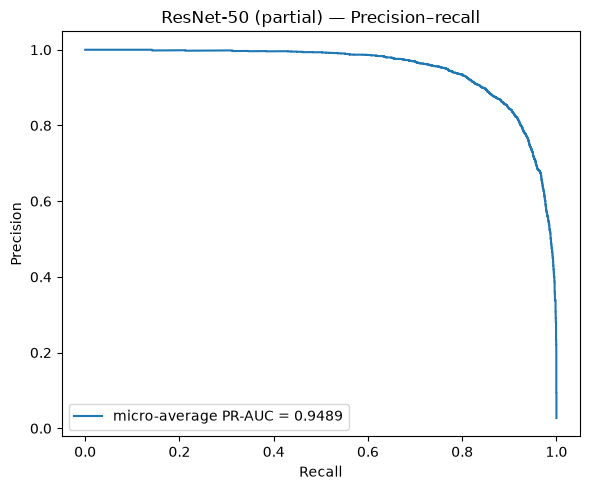

In [9]:
for name, result in test_results.items():
    predictions = test_predictions[name]
    title = f"{name} ({"partial"})"
    plot_confusion_matrix(
        result["confusion_matrix"], title, class_names=test_dataset.classes
    )
    plot_AUC_ROC(predictions["labels"], predictions["probabilities"], title)
    plot_AUC_PR(predictions["labels"], predictions["probabilities"], title)


# fine tune full model

Fine-tuning entire network: ConvNeXt Tiny
Trainable: 27,848,581/27,848,581 (100.0%)
Epoch 1/10: train_loss=3.5608, train_acc=0.0340, val_loss=3.2058, val_acc=0.1046
Epoch 2/10: train_loss=2.8614, train_acc=0.2609, val_loss=2.5339, val_acc=0.4185
Epoch 3/10: train_loss=2.1570, train_acc=0.5842, val_loss=1.8499, val_acc=0.7133
Epoch 4/10: train_loss=1.5012, train_acc=0.7680, val_loss=1.2705, val_acc=0.8288
Epoch 5/10: train_loss=1.0196, train_acc=0.8556, val_loss=0.9015, val_acc=0.8777
Epoch 6/10: train_loss=0.7123, train_acc=0.9022, val_loss=0.6809, val_acc=0.9062
Epoch 7/10: train_loss=0.5342, train_acc=0.9236, val_loss=0.5407, val_acc=0.9144
Epoch 8/10: train_loss=0.4282, train_acc=0.9338, val_loss=0.4547, val_acc=0.9212
Epoch 9/10: train_loss=0.3496, train_acc=0.9443, val_loss=0.3980, val_acc=0.9266
Epoch 10/10: train_loss=0.2887, train_acc=0.9575, val_loss=0.3513, val_acc=0.9361


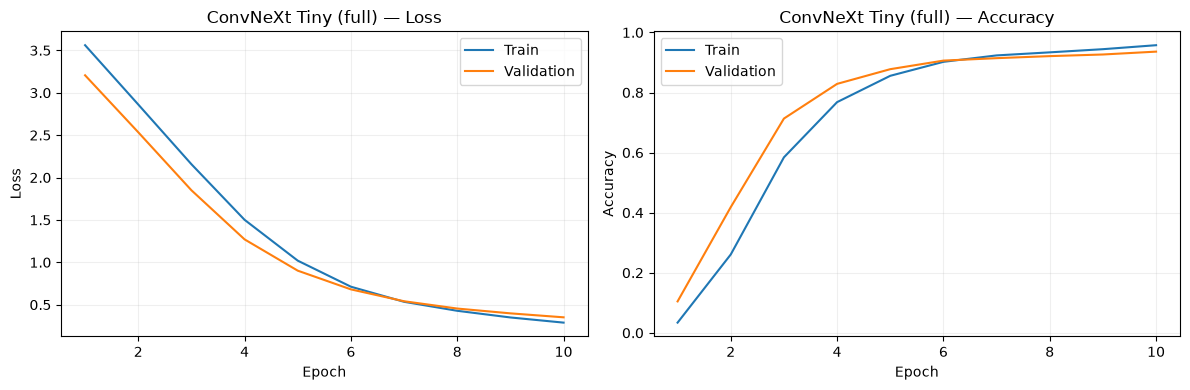

Best ConvNeXt Tiny: epoch=10, val_acc=0.9361
Fine-tuning entire network: Swin Transformer Tiny
Trainable: 27,547,807/27,547,807 (100.0%)
Epoch 1/10: train_loss=3.5593, train_acc=0.0659, val_loss=3.4792, val_acc=0.1318
Epoch 2/10: train_loss=3.4325, train_acc=0.1603, val_loss=3.3332, val_acc=0.2704
Epoch 3/10: train_loss=3.2789, train_acc=0.2942, val_loss=3.1520, val_acc=0.4198
Epoch 4/10: train_loss=3.0734, train_acc=0.4433, val_loss=2.9233, val_acc=0.5408
Epoch 5/10: train_loss=2.8234, train_acc=0.5533, val_loss=2.6221, val_acc=0.6304
Epoch 6/10: train_loss=2.4971, train_acc=0.6399, val_loss=2.2334, val_acc=0.6970
Epoch 7/10: train_loss=2.0963, train_acc=0.7048, val_loss=1.7734, val_acc=0.7649
Epoch 8/10: train_loss=1.6792, train_acc=0.7541, val_loss=1.3338, val_acc=0.8274
Epoch 9/10: train_loss=1.2988, train_acc=0.8142, val_loss=1.0009, val_acc=0.8546
Epoch 10/10: train_loss=1.0396, train_acc=0.8465, val_loss=0.7811, val_acc=0.8872


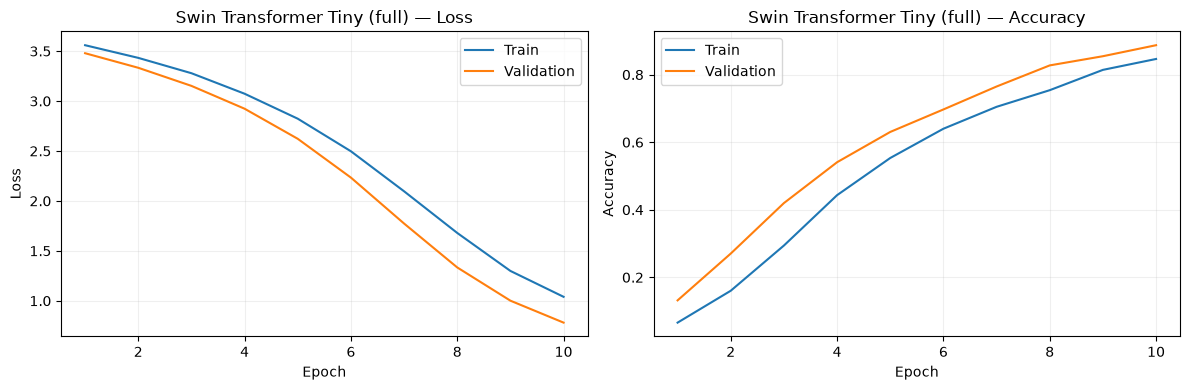

Best Swin Transformer Tiny: epoch=10, val_acc=0.8872
Fine-tuning entire network: ResNet-50
Trainable: 23,583,845/23,583,845 (100.0%)
Epoch 1/10: train_loss=3.6029, train_acc=0.0340, val_loss=3.5920, val_acc=0.0557
Epoch 2/10: train_loss=3.5817, train_acc=0.0550, val_loss=3.5725, val_acc=0.0774
Epoch 3/10: train_loss=3.5632, train_acc=0.0849, val_loss=3.5542, val_acc=0.1291
Epoch 4/10: train_loss=3.5447, train_acc=0.1080, val_loss=3.5365, val_acc=0.1549
Epoch 5/10: train_loss=3.5253, train_acc=0.1444, val_loss=3.5184, val_acc=0.1902
Epoch 6/10: train_loss=3.5040, train_acc=0.1950, val_loss=3.4984, val_acc=0.2147
Epoch 7/10: train_loss=3.4828, train_acc=0.2374, val_loss=3.4790, val_acc=0.2894
Epoch 8/10: train_loss=3.4630, train_acc=0.2741, val_loss=3.4574, val_acc=0.3424
Epoch 9/10: train_loss=3.4431, train_acc=0.3217, val_loss=3.4355, val_acc=0.3750
Epoch 10/10: train_loss=3.4218, train_acc=0.3611, val_loss=3.4147, val_acc=0.4103


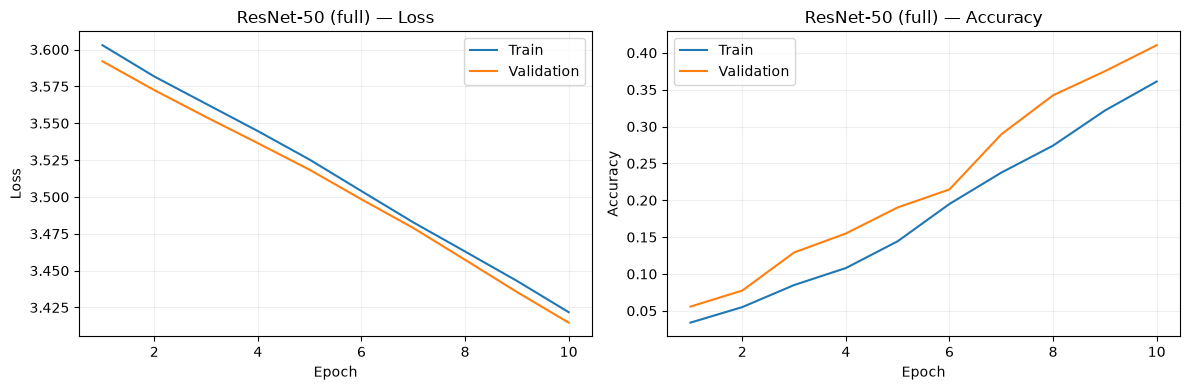

Best ResNet-50: epoch=10, val_acc=0.4103


In [ ]:
BACKBONE_LEARNING_RATE = 1e-5
HEAD_LEARNING_RATE = 1e-4

training_runs = {}
for model_name, (model_id, model) in models.items():
    print(f"Fine-tuning entire network: {model_name}")
    model.load_state_dict(initial_model_states[model_id])
    model.to(DEVICE)

    # Restore gradients for every layer (the earlier experiments froze many).
    for parameter in model.parameters():
        parameter.requires_grad = True

    head_params = list(model.get_classifier().parameters())
    head_ids = {id(param) for param in head_params}
    backbone_params = [
        param for param in model.parameters() if id(param) not in head_ids
    ]
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"Trainable: {trainable:,}/{total:,} ({trainable/total:.1%})")

    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": BACKBONE_LEARNING_RATE},
        {"params": head_params, "lr": HEAD_LEARNING_RATE},
    ])
    result_dir = repo_root / "results" / "classification" / "full" / model_id
    history = []
    best_val_accuracy = -1.0
    best_val_loss = float("inf")
    best_epoch = None

    for epoch in range(1, NUM_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_dataloader, CRITERION, optimizer, DEVICE
        )
        val_loss, val_acc = validate(model, val_dataloader, CRITERION, DEVICE)
        history.append({
            "epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc,
            "val_loss": val_loss, "val_accuracy": val_acc,
        })
        print(
            f"Epoch {epoch}/{NUM_EPOCHS}: train_loss={train_loss:.4f}, "
            f"train_acc={train_acc:.4f}, val_loss={val_loss:.4f}, val_acc={val_acc:.4f}"
        )

        if val_acc > best_val_accuracy or (
            val_acc == best_val_accuracy and val_loss < best_val_loss
        ):
            best_epoch = epoch
            best_val_accuracy = val_acc
            best_val_loss = val_loss
            save_checkpoint(
                result_dir / "best.pt", model, optimizer, epoch,
                {"loss": val_loss, "accuracy": val_acc},
                metadata={
                    "model_name": model_name, "model_id": model_id,
                    "dataset": dataset_name, "training_strategy": "full",
                    "backbone_learning_rate": BACKBONE_LEARNING_RATE,
                    "head_learning_rate": HEAD_LEARNING_RATE,
                    "image_size": IMAGE_SIZE,
                    "normalization_mean": mean, "normalization_std": std,
                    "split_seed": 42, "trainable_parameters": trainable,
                    "initialization": "pretrained_backbone_fresh_classifier",
                },
            )

        save_json(history, result_dir / "training_history.json")

    training_runs[model_name] = {
        "model_id": model_id, "history": history,
        "best_epoch": best_epoch, "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss,
    }
    plot_training_history(history, f"{model_name} (full)")
    print(f"Best {model_name}: epoch={best_epoch}, val_acc={best_val_accuracy:.4f}")


In [15]:
test_results = {}
test_predictions = {}
for model_name, (model_id, model) in models.items():
    result_dir = repo_root / "results" / "classification" / "full" / model_id
    checkpoint = load_checkpoint(result_dir / "best.pt", model, device=DEVICE)
    metrics, predictions = evaluate(
        model, test_dataloader, CRITERION, DEVICE, return_predictions=True
    )
    test_results[model_name] = metrics
    test_predictions[model_name] = predictions
    save_json(
        {
            "model": model_name,
            "checkpoint_epoch": checkpoint["epoch"],
            "best_validation": checkpoint["validation_metrics"],
            "test_metrics": metrics,
        },
        result_dir / "test_metrics.json",
    )
    save_predictions(predictions, result_dir / "test_predictions.npz")

comparison = display_metrics(test_results)
save_json(test_results, repo_root / "results" / "classification" / "full" / "comparison.json")


,Loss,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AP (macro OvR),ECE,Classes in AUC
Model,,,,,,,,,,,,
ConvNeXt Tiny,0.4150,0.9057,0.9122,0.9057,0.9043,0.9133,0.9057,0.9048,0.9980,0.9497,0.1340,37
Swin Transformer Tiny,0.8108,0.8678,0.8664,0.8668,0.8622,0.8678,0.8678,0.8635,0.9958,0.9015,0.3336,37
ResNet-50,3.4231,0.3990,0.5510,0.3967,0.3955,0.5521,0.3990,0.3973,0.9475,0.4661,0.3643,37


PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/classification/full/comparison.json')

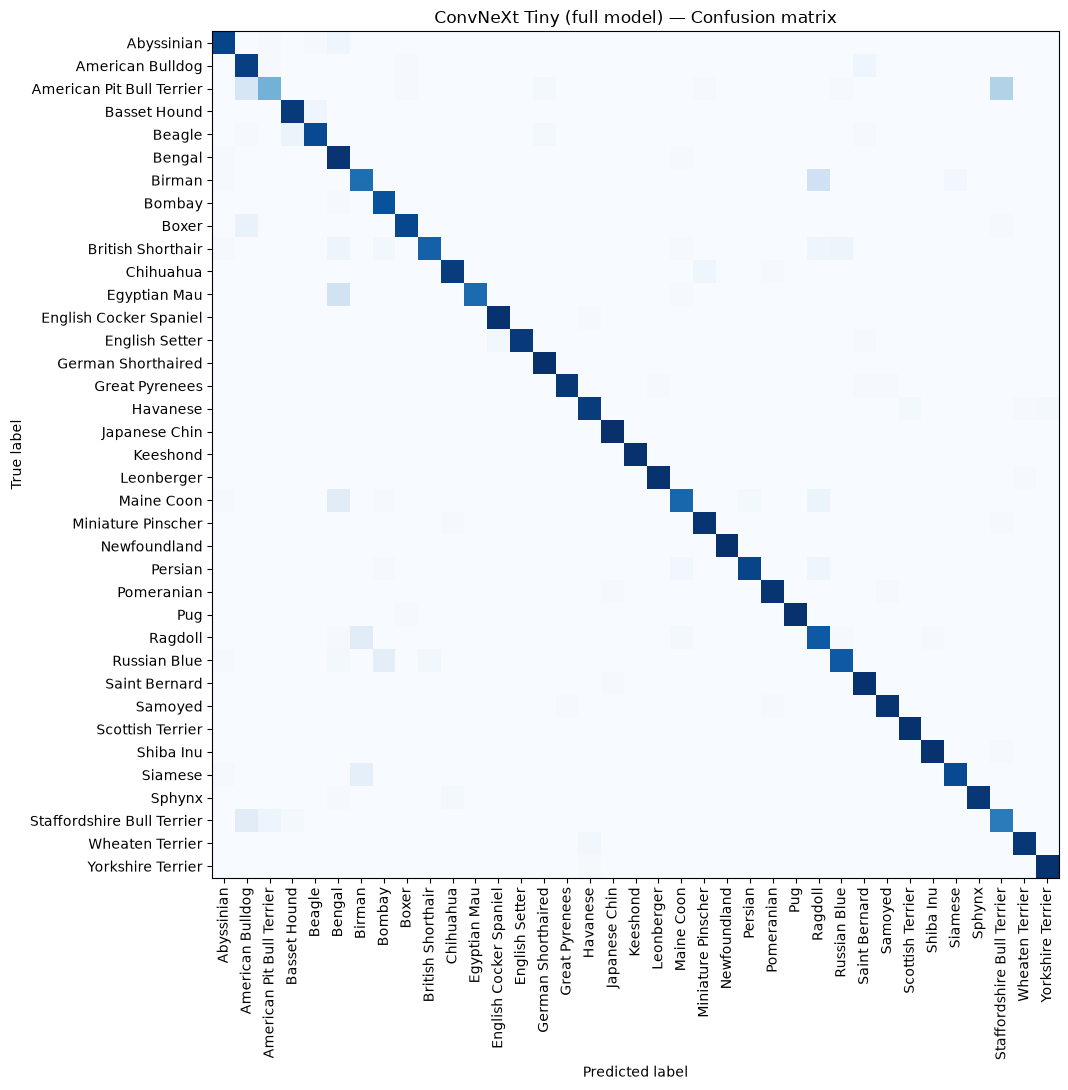

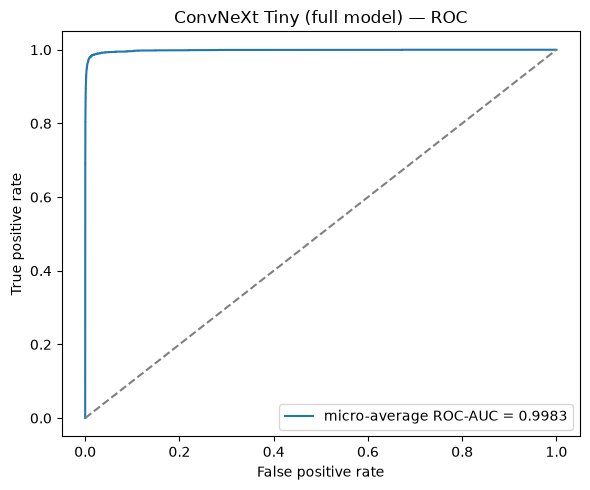

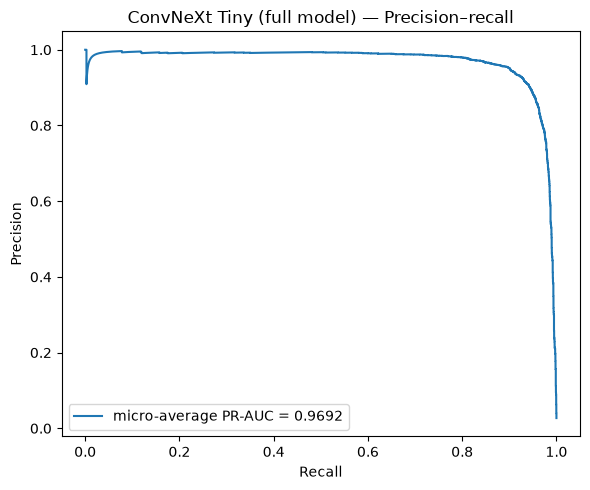

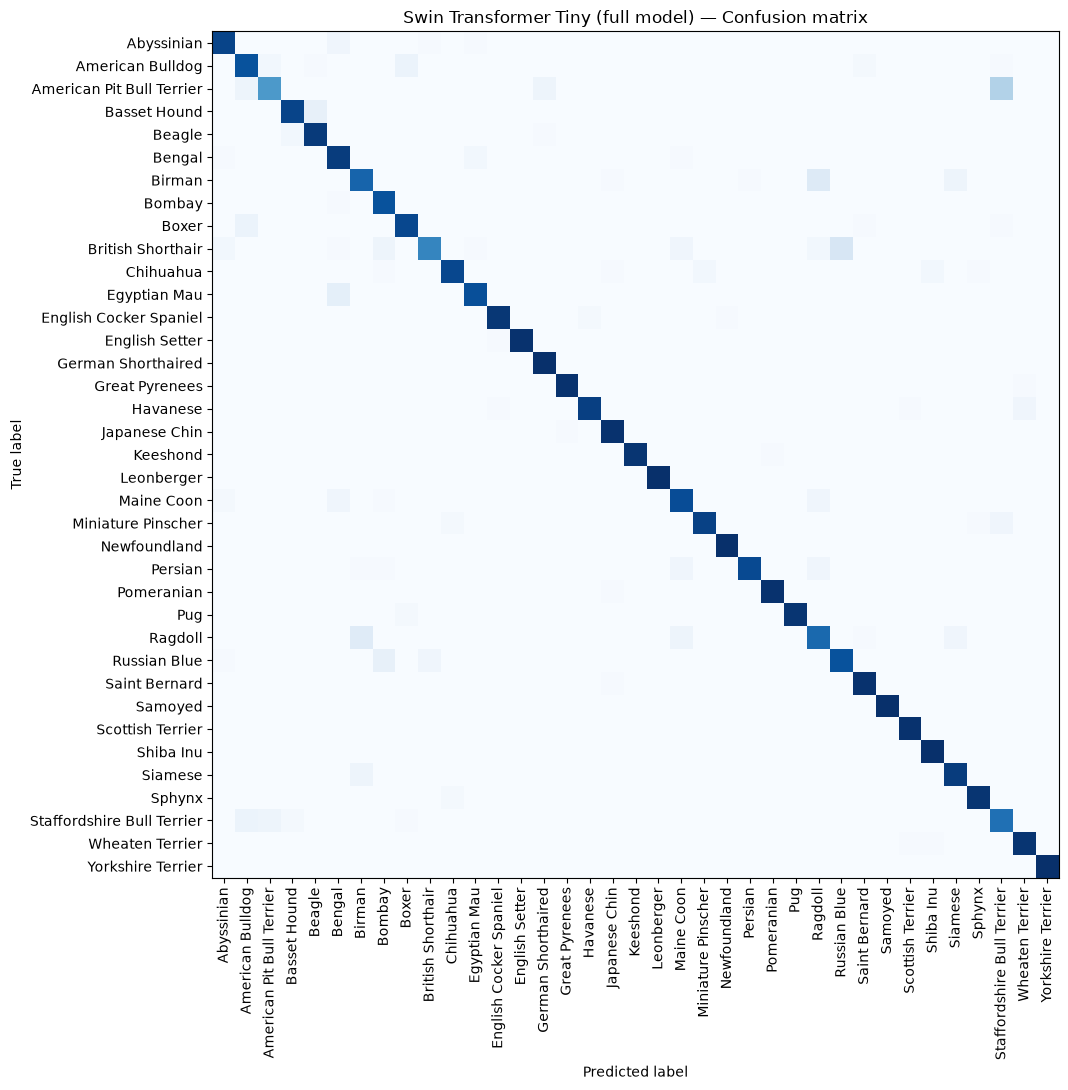

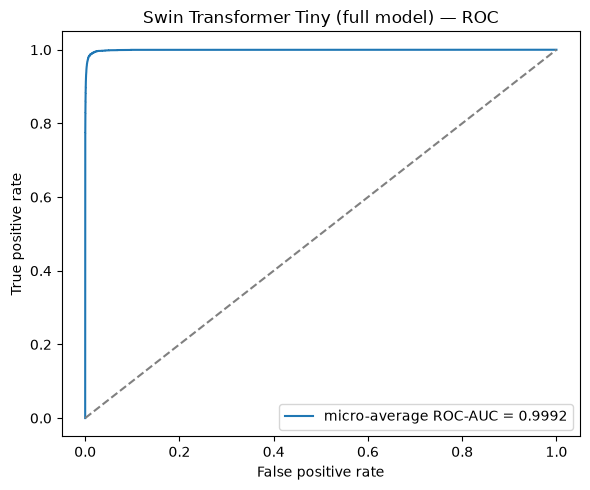

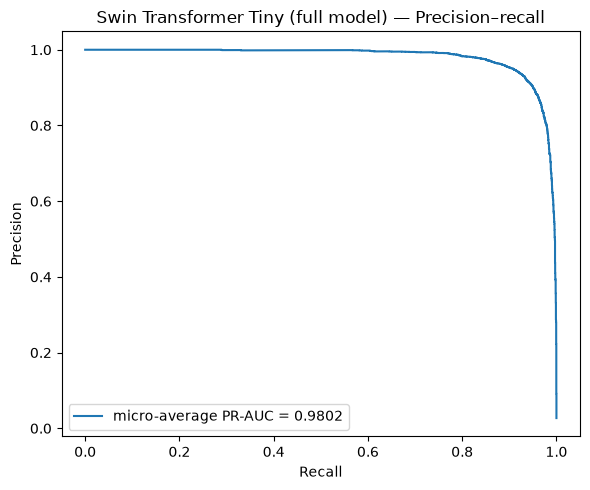

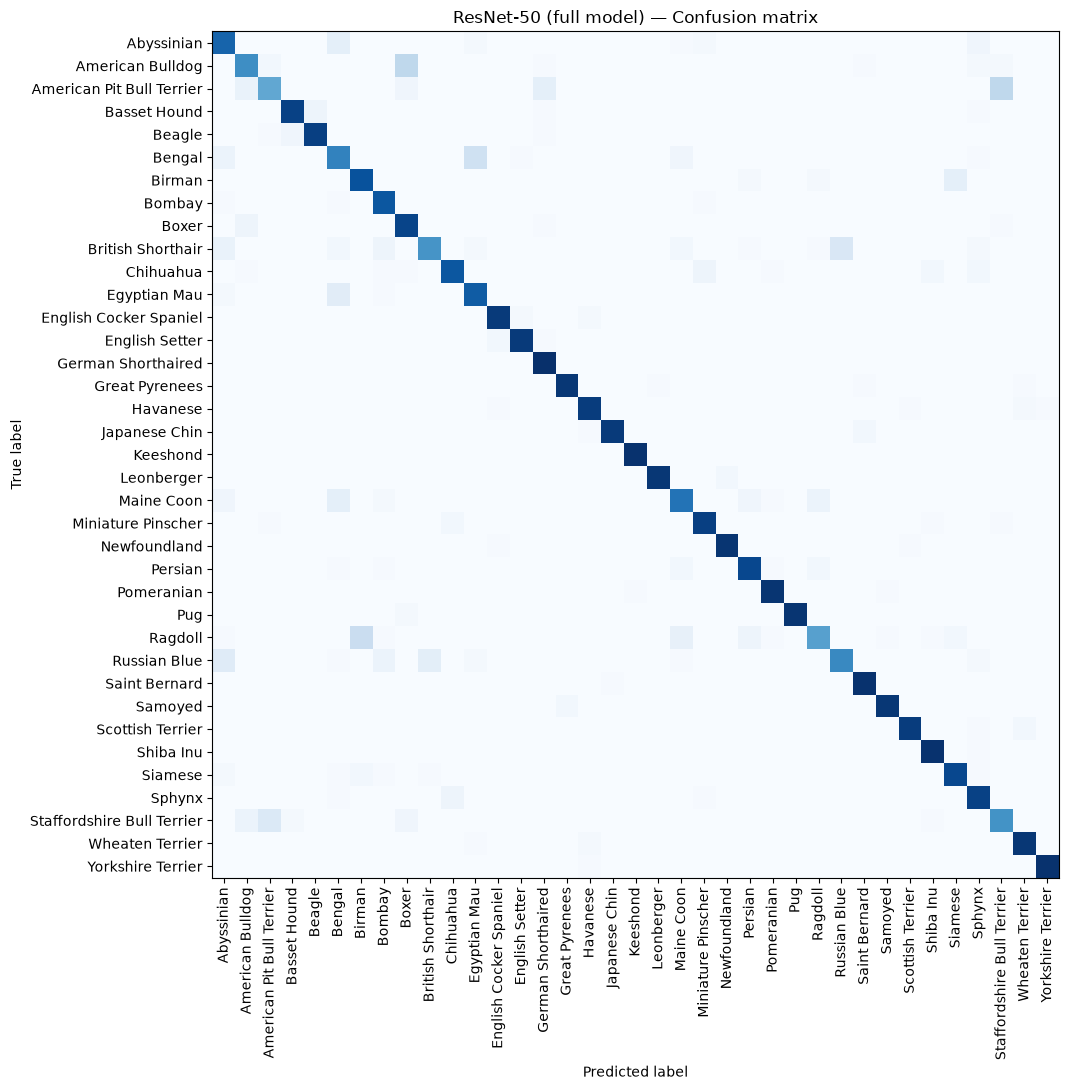

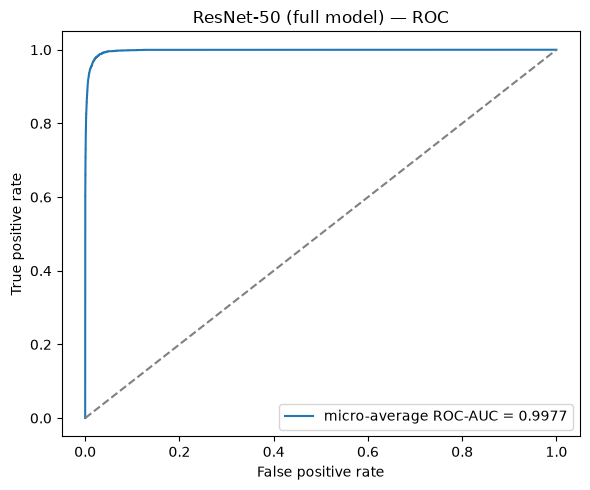

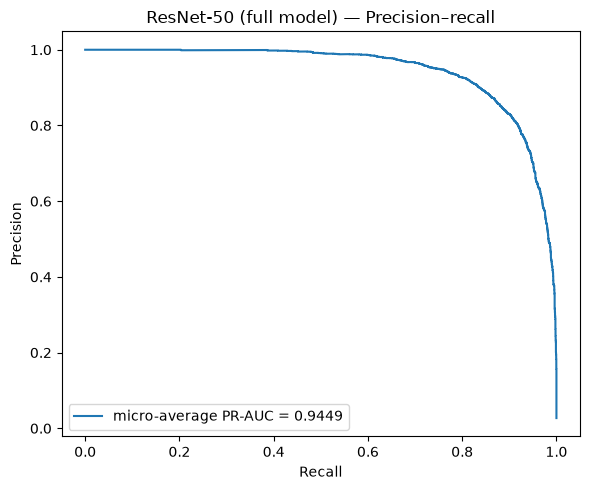

In [12]:
for name, result in test_results.items():
    predictions = test_predictions[name]
    title = f"{name} ({"full model"})"
    plot_confusion_matrix(
        result["confusion_matrix"], title, class_names=test_dataset.classes
    )
    plot_AUC_ROC(predictions["labels"], predictions["probabilities"], title)
    plot_AUC_PR(predictions["labels"], predictions["probabilities"], title)


# Comparison across fine-tuning strategies


In [13]:
import json

all_test_results = {}
for strategy in ("classifier_head", "partial", "full"):
    for model_name, (model_id, _) in models.items():
        path = (
            repo_root / "results" / "classification" / strategy
            / model_id / "test_metrics.json"
        )
        with path.open(encoding="utf-8") as file:
            saved_result = json.load(file)
        all_test_results[f"{strategy} — {model_name}"] = saved_result["test_metrics"]

all_comparison = display_metrics(all_test_results)
save_json(
    all_test_results, repo_root / "results" / "classification" / "comparison.json"
)


,Loss,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (macro OvR),PR-AP (macro OvR),ECE,Classes in AUC
Model,,,,,,,,,,,,
classifier_head — ConvNeXt Tiny,0.2737,0.9182,0.9192,0.9180,0.9170,0.9200,0.9182,0.9175,0.9984,0.9539,0.0538,37
classifier_head — Swin Transformer Tiny,0.5684,0.9087,0.9099,0.9082,0.9071,0.9108,0.9087,0.9078,0.9980,0.9486,0.2656,37
classifier_head — ResNet-50,1.4801,0.8945,0.8947,0.8940,0.8919,0.8955,0.8945,0.8925,0.9960,0.9043,0.6406,37
partial — ConvNeXt Tiny,0.2254,0.9354,0.9369,0.9351,0.9341,0.9378,0.9354,0.9347,0.9984,0.9674,0.0129,37
partial — Swin Transformer Tiny,0.2069,0.9286,0.9300,0.9278,0.9271,0.9304,0.9286,0.9277,0.9989,0.9686,0.0101,37
partial — ResNet-50,0.6397,0.8942,0.8950,0.8939,0.8913,0.8960,0.8942,0.8920,0.9969,0.9284,0.2680,37
full — ConvNeXt Tiny,0.2625,0.9248,0.9306,0.9245,0.9237,0.9315,0.9248,0.9243,0.9980,0.9643,0.0228,37
full — Swin Transformer Tiny,0.2158,0.9291,0.9306,0.9291,0.9277,0.9316,0.9291,0.9283,0.9988,0.9677,0.0110,37
full — ResNet-50,0.6583,0.8798,0.8801,0.8796,0.8766,0.8811,0.8798,0.8772,0.9967,0.9222,0.2688,37


PosixPath('/Users/kasrasadatsharifi/SideProjects/ConvNeXts/results/classification/comparison.json')